### Main file of the task 1: Image Resize

In [1]:
import torch
from datasets import ResizeDataset
from torch.utils.data import DataLoader, random_split
from models import ResizeNet
from loss import PixelLPIPSLoss
import torch.optim as optim
from tqdm import tqdm
import matplotlib.pyplot as plt
import cv2

Make sure to run `prepare_data.py` once to prepare the images.

In [2]:
DATA_PATH = "data/DIV2K_train_256"

In [3]:
def prepareDevice():
    device = torch.device("cpu")

    if torch.cuda.is_available():
        device = torch.device("cuda")
        torch.cuda.manual_seed(42)
        torch.cuda.manual_seed_all(42)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        print("Using CUDA")
    else:
        print("Using CPU")

    return device

In [4]:
DEVICE = prepareDevice()
BATCH_SIZE = 32
LEARNING_RATE = 0.0005
NUM_EPOCHS = 20

Using CUDA


In [5]:
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            total_loss += loss.item()
    avg_loss = total_loss / len(loader)
    return avg_loss

In [6]:
def train(model, train_dataloader, val_dataloader, criterion, optimizer, model_name="model"):
    best_val_loss = float("inf")

    for epoch in range(NUM_EPOCHS):
        model.train()
        running_loss = 0.0
        for _, (inputs, targets) in enumerate(tqdm(train_dataloader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS}")):
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        
        avg_train_loss = running_loss / len(train_dataloader)
        avg_val_loss = evaluate(model, val_dataloader, criterion)

        print(f"Epoch {epoch+1}/{NUM_EPOCHS} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

        if avg_val_loss < best_val_loss:
            torch.save(model.state_dict(), model_name + ".pth")
            best_val_loss = avg_val_loss

### For image of size 64x64

In [7]:
IMAGE_SIZE = 64
dataset = ResizeDataset(DATA_PATH, img_size=IMAGE_SIZE)
train_size = int(0.9 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])
train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
val_dataloader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
upscale_factor = 256 // IMAGE_SIZE
model = ResizeNet(upscale_factor=upscale_factor).to(DEVICE)
criterion = PixelLPIPSLoss(pixel_weight=0.5, lpips_weight=0.5, device=DEVICE)
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


c:\Users\Nel\OneDrive\Pulpit\mgr\sigk\venv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\Nel\OneDrive\Pulpit\mgr\sigk\venv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: c:\Users\Nel\OneDrive\Pulpit\mgr\sigk\venv\Lib\site-packages\lpips\weights\v0.1\alex.pth


In [8]:
train(model, train_dataloader, val_dataloader, criterion, optimizer, "resize_64")

Epoch 1/20: 100%|██████████| 23/23 [01:16<00:00,  3.33s/it]


Epoch 1/20 | Train Loss: 0.2875 | Val Loss: 0.3686


Epoch 2/20: 100%|██████████| 23/23 [01:18<00:00,  3.39s/it]


Epoch 2/20 | Train Loss: 0.2383 | Val Loss: 0.2487


Epoch 3/20: 100%|██████████| 23/23 [01:21<00:00,  3.55s/it]


...

Epoch 18/20 | Train Loss: 0.1856 | Val Loss: 0.1969


Epoch 19/20: 100%|██████████| 23/23 [01:17<00:00,  3.35s/it]


Epoch 19/20 | Train Loss: 0.1852 | Val Loss: 0.2018


Epoch 20/20: 100%|██████████| 23/23 [01:16<00:00,  3.34s/it]


Epoch 20/20 | Train Loss: 0.1819 | Val Loss: 0.2058


LR shape: torch.Size([1, 3, 64, 64]), Output shape: torch.Size([1, 3, 256, 256]), HR shape: torch.Size([1, 3, 256, 256])


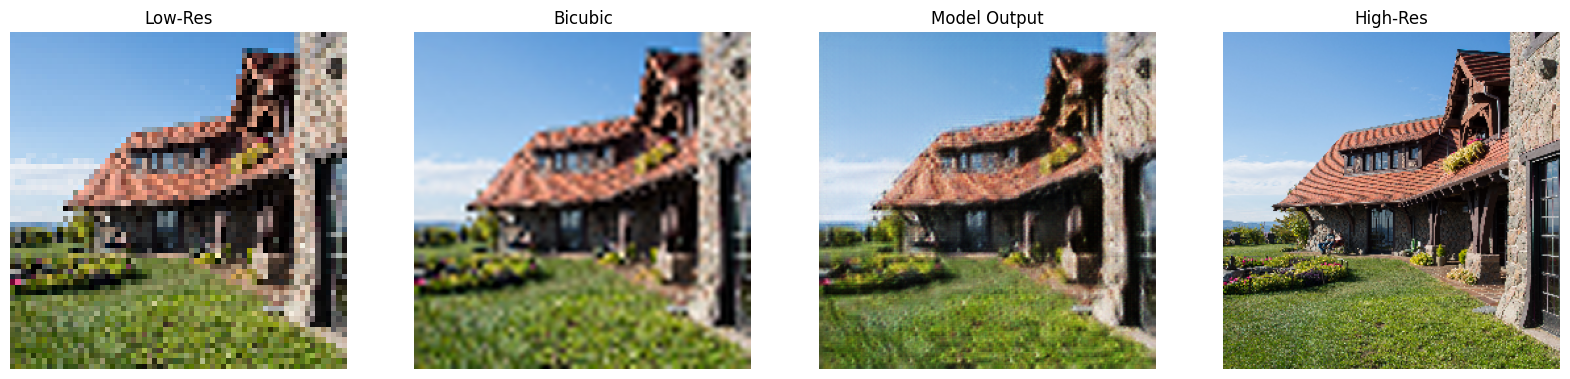

In [9]:
#An example
lr_tensor, hr_tensor = val_dataset[0]  
lr_tensor = lr_tensor.unsqueeze(0).to(DEVICE)  
hr_tensor = hr_tensor.unsqueeze(0).to(DEVICE)
model.eval()
with torch.no_grad():
    output_tensor = model(lr_tensor)
print(f"LR shape: {lr_tensor.shape}, Output shape: {output_tensor.shape}, HR shape: {hr_tensor.shape}")
def tensor_to_img(tensor):
    img = tensor.squeeze(0).cpu().permute(1,2,0).numpy()  # C,H,W -> H,W,C
    img = ((img + 1) / 2 * 255).clip(0,255).astype('uint8')
    return img
lr_np = tensor_to_img(lr_tensor)
output_np = tensor_to_img(output_tensor)
hr_np = tensor_to_img(hr_tensor)

bicubic_np = cv2.resize(lr_np, (hr_np.shape[1], hr_np.shape[0]), interpolation=cv2.INTER_CUBIC)

fig, axes = plt.subplots(1, 4, figsize=(20,5))
axes[0].imshow(lr_np); axes[0].set_title("Low-Res")
axes[1].imshow(bicubic_np); axes[1].set_title("Bicubic")
axes[2].imshow(output_np); axes[2].set_title("Model Output")
axes[3].imshow(hr_np); axes[3].set_title("High-Res")
for ax in axes:
    ax.axis("off")
plt.show()

### For image of size 32x32

In [10]:
IMAGE_SIZE_32 = 32
dataset = ResizeDataset(DATA_PATH, img_size=IMAGE_SIZE_32)
train_size = int(0.9 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])
train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
val_dataloader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
upscale_factor = 256 // IMAGE_SIZE_32
model = ResizeNet(upscale_factor=upscale_factor).to(DEVICE)
criterion = PixelLPIPSLoss(pixel_weight=0.5, lpips_weight=0.5, device=DEVICE)
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
Loading model from: c:\Users\Nel\OneDrive\Pulpit\mgr\sigk\venv\Lib\site-packages\lpips\weights\v0.1\alex.pth


In [11]:
train(model, train_dataloader, val_dataloader, criterion, optimizer, model_name="resize_32")

Epoch 1/20: 100%|██████████| 23/23 [01:12<00:00,  3.16s/it]


Epoch 1/20 | Train Loss: 0.3805 | Val Loss: 0.4925


Epoch 2/20: 100%|██████████| 23/23 [01:11<00:00,  3.11s/it]


Epoch 2/20 | Train Loss: 0.3319 | Val Loss: 0.3422


Epoch 3/20: 100%|██████████| 23/23 [01:10<00:00,  3.07s/it]


...

Epoch 18/20 | Train Loss: 0.2587 | Val Loss: 0.2833


Epoch 19/20: 100%|██████████| 23/23 [01:13<00:00,  3.19s/it]


Epoch 19/20 | Train Loss: 0.2559 | Val Loss: 0.2906


Epoch 20/20: 100%|██████████| 23/23 [01:11<00:00,  3.11s/it]


Epoch 20/20 | Train Loss: 0.2509 | Val Loss: 0.2865


LR shape: torch.Size([1, 3, 32, 32]), Output shape: torch.Size([1, 3, 256, 256]), HR shape: torch.Size([1, 3, 256, 256])


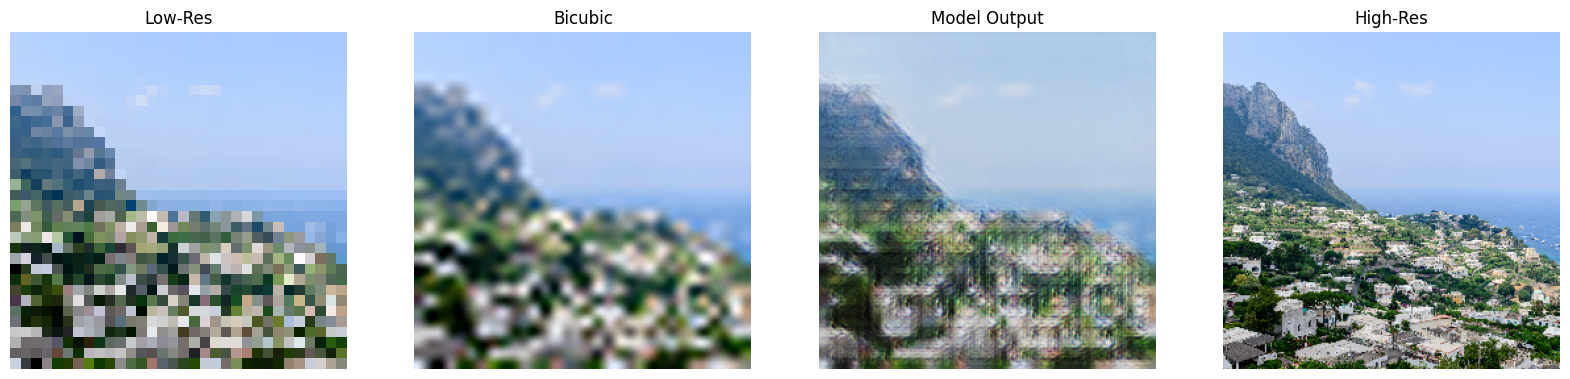

In [12]:
#An example
lr_tensor, hr_tensor = val_dataset[0]  
lr_tensor = lr_tensor.unsqueeze(0).to(DEVICE)  
hr_tensor = hr_tensor.unsqueeze(0).to(DEVICE)
model.eval()
with torch.no_grad():
    output_tensor = model(lr_tensor)
print(f"LR shape: {lr_tensor.shape}, Output shape: {output_tensor.shape}, HR shape: {hr_tensor.shape}")
def tensor_to_img(tensor):
    img = tensor.squeeze(0).cpu().permute(1,2,0).numpy()  # C,H,W -> H,W,C
    img = ((img + 1) / 2 * 255).clip(0,255).astype('uint8')
    return img
lr_np = tensor_to_img(lr_tensor)
output_np = tensor_to_img(output_tensor)
hr_np = tensor_to_img(hr_tensor)

bicubic_np = cv2.resize(lr_np, (hr_np.shape[1], hr_np.shape[0]), interpolation=cv2.INTER_CUBIC)

fig, axes = plt.subplots(1, 4, figsize=(20,5))
axes[0].imshow(lr_np); axes[0].set_title("Low-Res")
axes[1].imshow(bicubic_np); axes[1].set_title("Bicubic")
axes[2].imshow(output_np); axes[2].set_title("Model Output")
axes[3].imshow(hr_np); axes[3].set_title("High-Res")
for ax in axes:
    ax.axis("off")
plt.show()